# Bitcoin (BTC-USD) ARIMA Time Series Modeling & Forecasting (Trained Till Dec 31, 2025)

This notebook performs comprehensive **Time Series Modeling, Stationarity Testing, Order Selection, Backtesting, Residual Diagnostics, and Multi-Step Forecasting** for Bitcoin (`BTC-USD`) closing prices using **ARIMA (AutoRegressive Integrated Moving Average)**, trained strictly up to **December 31, 2025**.

### Workflow Pipeline:
1. **Data Acquisition & Preprocessing**: Load historical daily Bitcoin market prices, parse timestamps, establish daily frequency (`freq='D'`), and filter data up to `2025-12-31`.
2. **Stationarity Analysis & Differencing**: Execute Augmented Dickey-Fuller (ADF) tests on raw prices vs. 1st differenced series (`d=1`), and plot Autocorrelation (ACF) & Partial Autocorrelation (PACF) functions.
3. **Automated Model Identification**: Utilize `pmdarima.auto_arima` to perform stepwise AIC/BIC minimization across candidate ARIMA orders `(p, d, q)`.
4. **Out-of-Sample Backtesting (2025 Test Evaluation)**: Partition dataset into Train (`<= 2024-12-31`) and Test (`2025-01-01` to `2025-12-31`). Evaluate 1-step out-of-sample forecast accuracy using RMSE, MAE, MAPE, $R^2$, and Directional Accuracy.
5. **Final Model Fitting & Residual Diagnostics**: Train the optimal ARIMA model on the full historical dataset up to Dec 31, 2025. Analyze standardized residuals, Q-Q plots, error distributions, and Ljung-Box test.
6. **Multi-Step Out-of-Sample Forecasting**: Generate 90-day forward projections into 2026 with 95% confidence intervals and export plots to `plots/`.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
import pmdarima as pm
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import json
import warnings
warnings.filterwarnings('ignore')

# Plot Aesthetics
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 11

print("Time series modeling packages successfully loaded.")


Time series modeling packages successfully loaded.


## Step 1: Data Acquisition & Preprocessing (Filtered Till Dec 31, 2025)

In [2]:
# Load data
data_path = '../bitcoin_data.csv' if os.path.exists('../bitcoin_data.csv') else '../data/bitcoin_data.csv'
if not os.path.exists(data_path):
    data_path = 'bitcoin_data.csv'

df = pd.read_csv(data_path)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Filter data strictly till 31st Dec 2025
df_filtered = df[df['Date'] <= '2025-12-31'].copy()
df_filtered.set_index('Date', inplace=True)
price_series = df_filtered['Close'].asfreq('D')

# Forward fill any missing calendar date values
price_series = price_series.ffill()

print(f"Data range for ARIMA training: {price_series.index.min().strftime('%Y-%m-%d')} to {price_series.index.max().strftime('%Y-%m-%d')}")
print(f"Total daily observations: {len(price_series)}")
price_series.tail()


Data range for ARIMA training: 2018-07-19 to 2025-12-30
Total daily observations: 2722


Date
2025-12-26    87301.429688
2025-12-27    87802.156250
2025-12-28    87835.835938
2025-12-29    87138.140625
2025-12-30    88430.132812
Freq: D, Name: Close, dtype: float64

## Step 2: Stationarity Tests & Autocorrelation Analysis (ACF / PACF)

=== Stationarity Test Results (ADF) ===
Raw Series ADF Statistic:       -0.8781 (p-value: 0.7951)
1st Difference ADF Statistic:   -9.5444 (p-value: 0.0000)


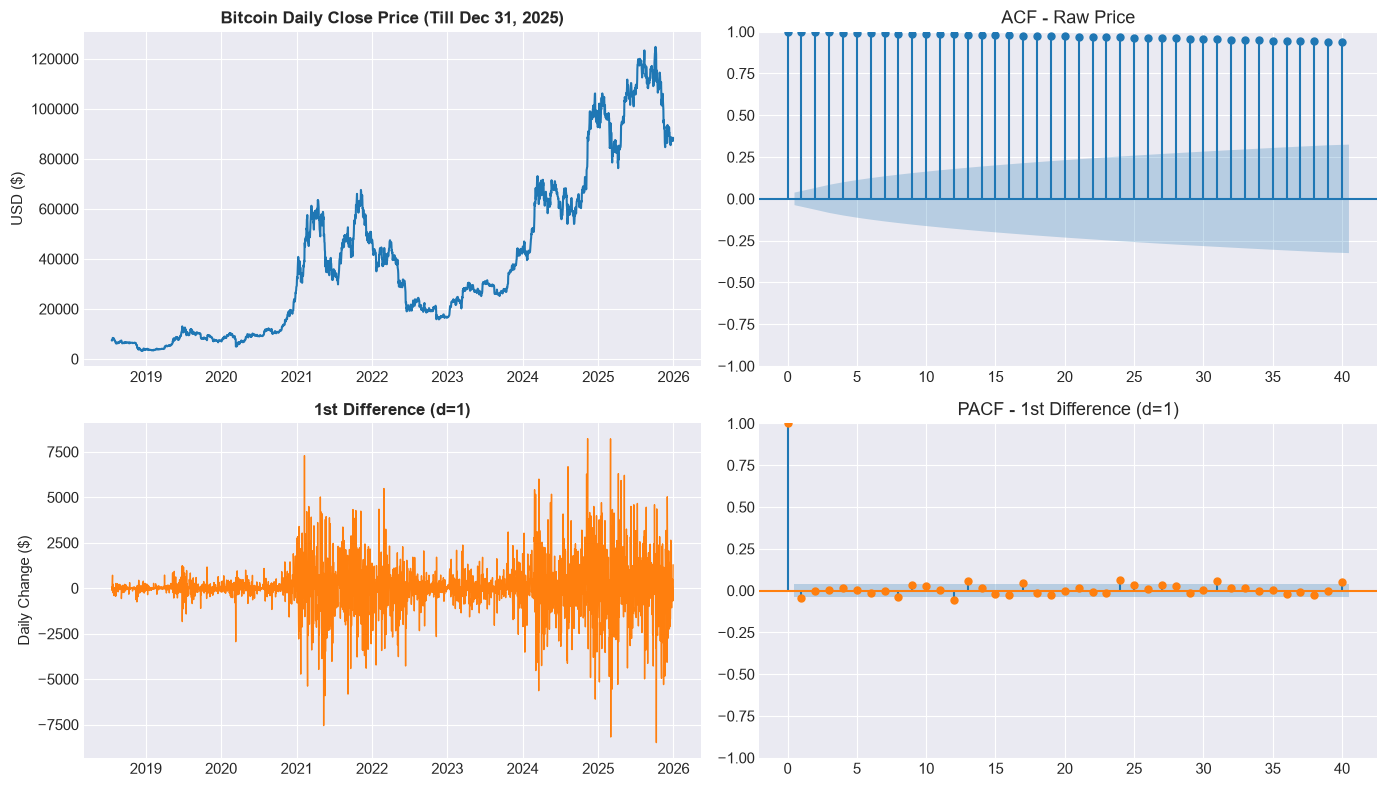

In [3]:
# Augmented Dickey-Fuller (ADF) Test
adf_raw = adfuller(price_series.dropna())
diff_series = price_series.diff().dropna()
adf_diff = adfuller(diff_series)

print("=== Stationarity Test Results (ADF) ===")
print(f"Raw Series ADF Statistic:       {adf_raw[0]:.4f} (p-value: {adf_raw[1]:.4f})")
print(f"1st Difference ADF Statistic:   {adf_diff[0]:.4f} (p-value: {adf_diff[1]:.4f})")

# Plot ACF & PACF
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(price_series, color='#1f77b4', linewidth=1.5)
axes[0, 0].set_title("Bitcoin Daily Close Price (Till Dec 31, 2025)", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("USD ($)")

plot_acf(price_series.dropna(), ax=axes[0, 1], lags=40, color='#1f77b4', title="ACF - Raw Price")

axes[1, 0].plot(diff_series, color='#ff7f0e', linewidth=1)
axes[1, 0].set_title("1st Difference (d=1)", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Daily Change ($)")

plot_pacf(diff_series.dropna(), ax=axes[1, 1], lags=40, color='#ff7f0e', title="PACF - 1st Difference (d=1)")

plt.tight_layout()
os.makedirs('../plots', exist_ok=True)
plt.savefig('../plots/arima_acf_pacf.png', dpi=300)
plt.show()


## Step 3: Automated ARIMA Order Identification (`pmdarima.auto_arima`)

In [4]:
# Stepwise grid search to find optimal (p, d, q) order
print("--- Running Stepwise Auto-ARIMA Search ---")
auto_model = pm.auto_arima(
    price_series,
    start_p=0, start_q=0,
    max_p=5, max_q=5, d=1,
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True
)

order = auto_model.order
print(f"\nOptimal ARIMA Order Selected: {order}")
print(auto_model.summary())


--- Running Stepwise Auto-ARIMA Search ---
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=46916.333, Time=0.06 sec


 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=46912.797, Time=0.17 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=46912.815, Time=0.18 sec


 ARIMA(0,1,0)(0,0,0)[0]             : AIC=46915.672, Time=0.04 sec


 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=46914.798, Time=0.21 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=46914.800, Time=0.18 sec


 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=46916.800, Time=0.23 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=46912.267, Time=0.08 sec
 ARIMA(2,1,0)(0,0,0)[0]             : AIC=46914.267, Time=0.11 sec


 ARIMA(1,1,1)(0,0,0)[0]             : AIC=46914.269, Time=0.10 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=46912.287, Time=0.08 sec


 ARIMA(2,1,1)(0,0,0)[0]             : AIC=46916.268, Time=0.14 sec

Best model:  ARIMA(1,1,0)(0,0,0)[0]          
Total fit time: 1.643 seconds

Optimal ARIMA Order Selected: (1, 1, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2722
Model:               SARIMAX(1, 1, 0)   Log Likelihood              -23454.133
Date:                Mon, 05 Oct 2026   AIC                          46912.267
Time:                        20:00:26   BIC                          46924.084
Sample:                    07-19-2018   HQIC                         46916.538
                         - 12-30-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0445    

## Step 4: Out-of-Sample Backtesting & Model Evaluation (2025 Test Split)

Train Set: 2358 observations | Test Set (2025): 364 observations

=== 2025 Out-of-Sample Backtest Performance ===
RMSE:                   $2,137.35
MAE:                    $1,563.43
MAPE:                   1.57%
R^2 Score:              0.9668
Directional Accuracy:   48.48%


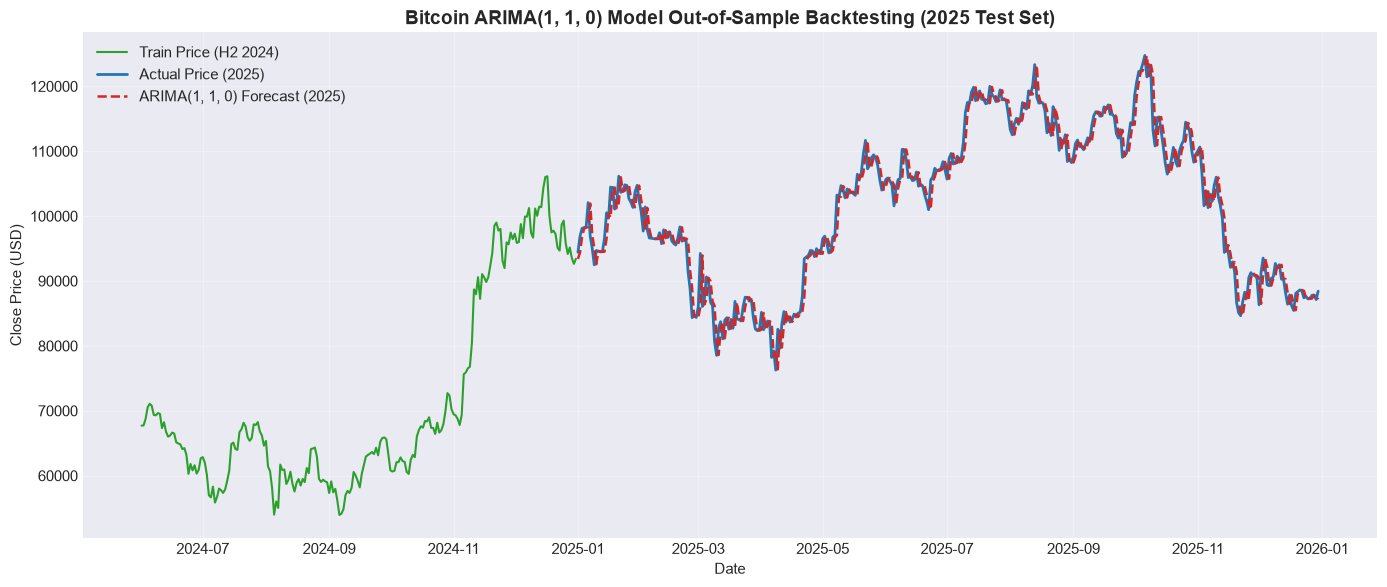

In [5]:
# Split dataset: Train (up to 2024-12-31), Test (2025-01-01 to 2025-12-31)
train_series = price_series[:'2024-12-31']
test_series = price_series['2025-01-01':'2025-12-31']

print(f"Train Set: {len(train_series)} observations | Test Set (2025): {len(test_series)} observations")

# Fast 1-step out-of-sample backtest using statsmodels append
fitted_train = ARIMA(train_series, order=order).fit()
res_test = fitted_train.append(test_series, refit=False)
predictions_series = res_test.fittedvalues[test_series.index]

# Evaluation Metrics
rmse = np.sqrt(mean_squared_error(test_series, predictions_series))
mae = mean_absolute_error(test_series, predictions_series)
mape = mean_absolute_percentage_error(test_series, predictions_series) * 100
r2 = r2_score(test_series, predictions_series)

act_dir = np.sign(test_series.diff().dropna())
pred_dir = np.sign(predictions_series.diff().dropna())
dir_acc = np.mean(act_dir == pred_dir) * 100

print("\n=== 2025 Out-of-Sample Backtest Performance ===")
print(f"RMSE:                   ${rmse:,.2f}")
print(f"MAE:                    ${mae:,.2f}")
print(f"MAPE:                   {mape:.2f}%")
print(f"R^2 Score:              {r2:.4f}")
print(f"Directional Accuracy:   {dir_acc:.2f}%")

# Plot 2025 Backtest Results
plt.figure(figsize=(14, 6))
plt.plot(train_series['2024-06-01':].index, train_series['2024-06-01':], label='Train Price (H2 2024)', color='#2ca02c', linewidth=1.5)
plt.plot(test_series.index, test_series, label='Actual Price (2025)', color='#1f77b4', linewidth=2)
plt.plot(test_series.index, predictions_series, label=f'ARIMA{order} Forecast (2025)', color='#d62728', linestyle='--', linewidth=1.8)
plt.title(f"Bitcoin ARIMA{order} Model Out-of-Sample Backtesting (2025 Test Set)", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Close Price (USD)")
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../plots/arima_test_evaluation.png', dpi=300)
plt.show()


## Step 5: Final Model Fitting & Residual Diagnostics (Till Dec 31, 2025)

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 2722
Model:                 ARIMA(1, 1, 0)   Log Likelihood              -23454.133
Date:                Mon, 05 Oct 2026   AIC                          46912.267
Time:                        20:00:28   BIC                          46924.084
Sample:                    07-19-2018   HQIC                         46916.538
                         - 12-30-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0445      0.012     -3.653      0.000      -0.068      -0.021
sigma2      1.797e+06   2.38e+04     75.456      0.000    1.75e+06    1.84e+06
Ljung-Box (L1) (Q):                   0.00   Jarque-

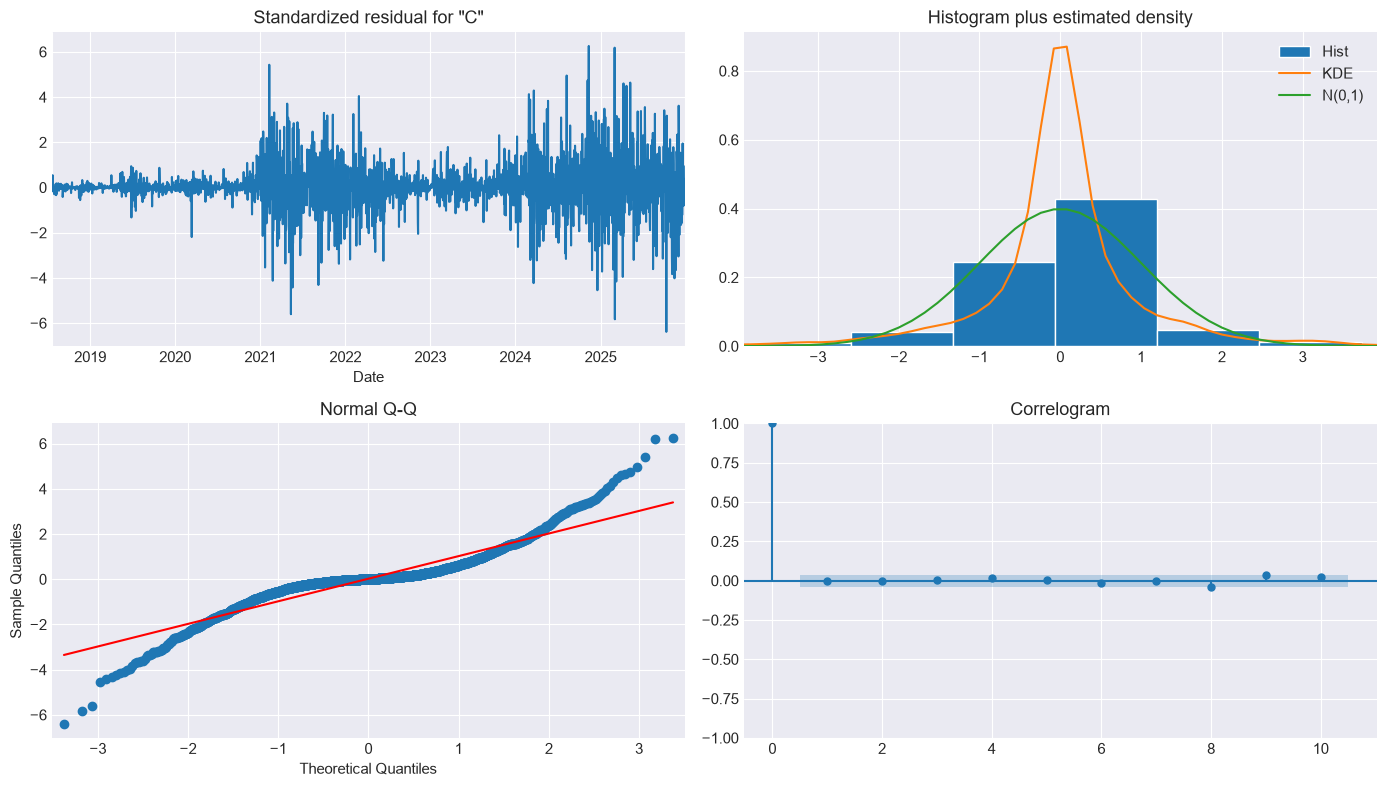

In [6]:
# Train final model on complete dataset up to Dec 31, 2025
final_model = ARIMA(price_series, order=order).fit()
print(final_model.summary())

# Diagnostic Plots
fig = final_model.plot_diagnostics(figsize=(14, 8))
plt.tight_layout()
plt.savefig('../plots/arima_residual_diagnostics.png', dpi=300)
plt.show()


## Step 6: Multi-Step Out-of-Sample Price Forecasting (90 Days into 2026)

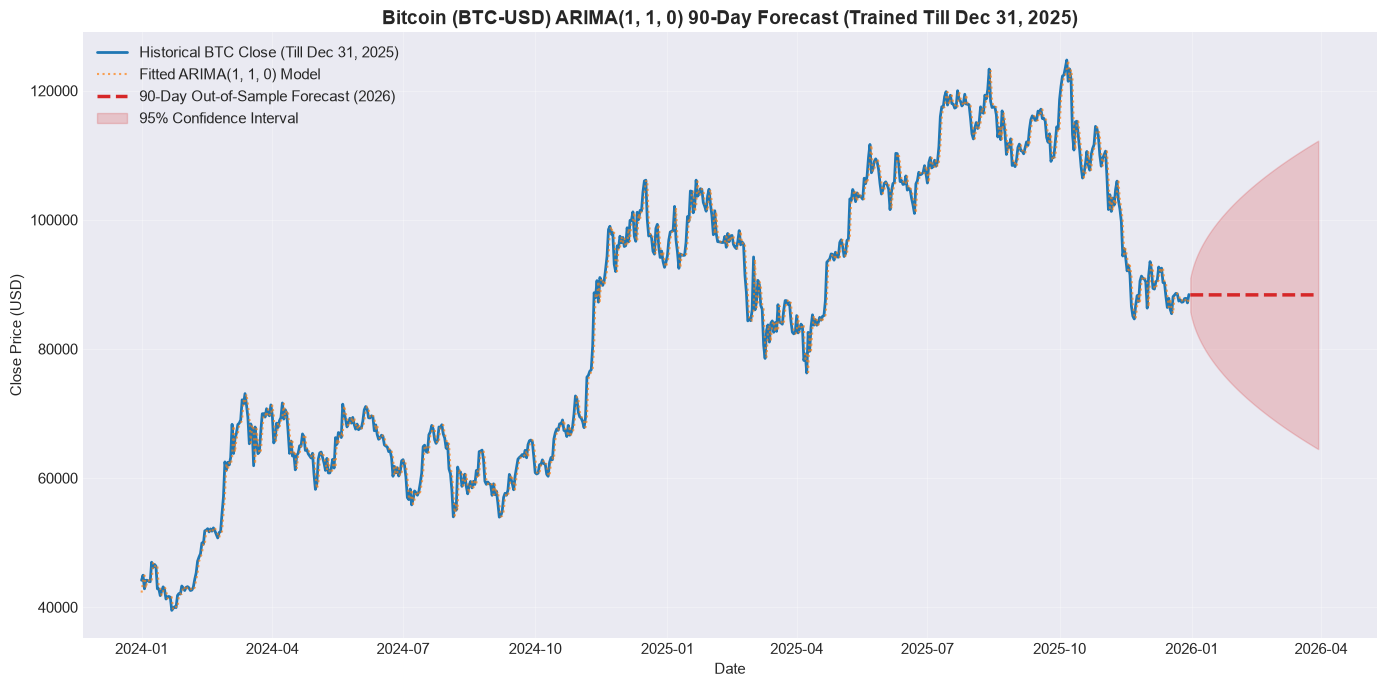

Forecast Horizon: 2025-12-31 to 2026-03-30
End-of-Horizon Projected Price: $88,375.15
95% Confidence Interval: [$64,496.45, $112,253.85]


In [7]:
# 90-Day Out-of-Sample Forecast into 2026
forecast_steps = 90
forecast_res = final_model.get_forecast(steps=forecast_steps)
forecast_mean = forecast_res.predicted_mean
forecast_ci = forecast_res.conf_int(alpha=0.05)

future_dates = pd.date_range(start=price_series.index.max() + pd.Timedelta(days=1), periods=forecast_steps, freq='D')
forecast_mean.index = future_dates
forecast_ci.index = future_dates

plt.figure(figsize=(14, 7))
plot_start = '2024-01-01'
plt.plot(price_series[plot_start:].index, price_series[plot_start:], label='Historical BTC Close (Till Dec 31, 2025)', color='#1f77b4', linewidth=2)
plt.plot(final_model.fittedvalues[plot_start:].index, final_model.fittedvalues[plot_start:], label=f'Fitted ARIMA{order} Model', color='#ff7f0e', alpha=0.7, linestyle=':')
plt.plot(forecast_mean.index, forecast_mean, label=f'90-Day Out-of-Sample Forecast (2026)', color='#d62728', linewidth=2.5, linestyle='--')
plt.fill_between(forecast_ci.index, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='#d62728', alpha=0.2, label='95% Confidence Interval')

plt.title(f"Bitcoin (BTC-USD) ARIMA{order} 90-Day Forecast (Trained Till Dec 31, 2025)", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Close Price (USD)")
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../plots/arima_forecast_2025_dec.png', dpi=300)
plt.show()

print(f"Forecast Horizon: {future_dates[0].strftime('%Y-%m-%d')} to {future_dates[-1].strftime('%Y-%m-%d')}")
print(f"End-of-Horizon Projected Price: ${forecast_mean.iloc[-1]:,.2f}")
print(f"95% Confidence Interval: [${forecast_ci.iloc[-1, 0]:,.2f}, ${forecast_ci.iloc[-1, 1]:,.2f}]")
